
# Anthropic IPO: Monte Carlo Trading Strategy Analysis

## Research Objective

To investigate whether delaying entry after a technology
IPO improves risk-adjusted returns and reduces downside risk.

## Hypothesis

Waiting 3–5 trading days after an IPO may reduce exposure
to initial price volatility compared with buying immediately.

## Strategies

- Strategy A: Buy on day 0
- Strategy B: Buy on day 3
- Strategy C: Buy on day 5

All strategies exit at the end of trading day 30.

## Methodology

1. Collect historical data from comparable technology IPOs.
2. Analyse post-IPO returns and volatility.
3. Generate Monte Carlo price scenarios.
4. Apply each strategy to the same scenarios.
5. Compare returns, probability of loss and drawdowns.

## Important Limitation

This is a hypothetical analysis based on comparable IPOs.
It does not predict Anthropic's future share price.


We cannot simply tell the computer to generate 10,000 random prices and assume they represent Anthropic.We need evidence of how real stocks behaved after going public.

Our first experiment will be examining three technology companies
1. Arm Holdings (ARM)
2. Reddit(RDDT)
3. Snowflake(SNOW)
4. SpaceX (SPCX)

Generating OHLCV data for ARM 

In [21]:

import yfinance as yf
import pandas as pd

# First company: ARM
arm = yf.download(
    "ARM",
    start="2023-09-14",  #arm went public on 14th sep 2023 
    end="2023-12-01",    #choice to capture roughly the first two and a half month trading
    auto_adjust=True,    #for omitting stock splits
    progress=False
)


In [23]:
print(arm.shape)
print(arm.head())
print(arm.tail())

(55, 5)
Price           Close       High        Low       Open     Volume
Ticker            ARM        ARM        ARM        ARM        ARM
Date                                                             
2023-09-14  63.590000  66.279999  55.540001  56.099998  130534500
2023-09-15  60.750000  69.000000  60.750000  68.629997   74753100
2023-09-18  58.000000  58.741001  55.020000  57.950001   34571900
2023-09-19  55.169998  56.779999  53.880001  56.250000   18308600
2023-09-20  52.910000  55.400002  51.520000  55.169998   16369500
Price           Close       High        Low       Open   Volume
Ticker            ARM        ARM        ARM        ARM      ARM
Date                                                           
2023-11-24  63.880001  64.199997  61.410000  61.500000  6004900
2023-11-27  61.000000  63.689999  60.990002  63.049999  6681900
2023-11-28  61.919998  62.680000  60.790001  60.840000  4106900
2023-11-29  62.209999  63.410000  61.689999  62.520000  3642400
2023-11-30  61.5

Now We're standardising our research window, for every IPO we analyse, we'll initially examine its first 30 trading days.

In [26]:
arm_30 = arm.head(30)

print(arm_30.shape)
print(arm_30.tail())

(30, 5)
Price           Close       High        Low       Open   Volume
Ticker            ARM        ARM        ARM        ARM      ARM
Date                                                           
2023-10-19  49.740002  52.700001  49.529999  52.000000  4553400
2023-10-20  47.869999  49.740002  46.500000  49.740002  8089100
2023-10-23  50.209999  51.880001  46.500000  47.220001  9979300
2023-10-24  52.369999  52.891998  51.049999  52.000000  7211700
2023-10-25  49.439999  52.790001  49.310001  52.700001  4518800


ARM's closing price was substantially lower by the end of our observation period starting at day 1 from 63.59 to Day 30 at 49.44

We need to distinguish two types of returns :
1. Open to close return
2. Close to close return (We use this for Monte Carlo Model as they capture both overnight and intraday price movements) 

In [32]:

# Extract closing prices
arm_close = arm_30["Close"]

# Calculate daily close-to-close returns
arm_returns = arm_close.pct_change()

print(arm_returns.head())


Ticker           ARM
Date                
2023-09-14       NaN
2023-09-15 -0.044661
2023-09-18 -0.045267
2023-09-19 -0.048793
2023-09-20 -0.040964


ARM experienced four consecutive negative close-to-close returns immediately after its IPO.

Now lets calculate average return and volatility 

Average daily return (mean): The average percentage gain or loss per trading day.

Daily volatility (standard deviation): How much daily returns fluctuate around their average.

In [37]:

# Remove the first missing return
arm_returns_clean = arm_returns.dropna()

# Calculate average daily return
mean_return = arm_returns_clean.mean()

# Calculate daily volatility
daily_volatility = arm_returns_clean.std()

print("Average daily return:")
print(mean_return)

print("Daily volatility:")
print(daily_volatility)


Average daily return:
Ticker
ARM   -0.008075
dtype: float64
Daily volatility:
Ticker
ARM    0.034305
dtype: float64


We can see that ARM lost an average of 0.81% per day, with its daily returns fluctuating by around 3.43% during its first 30 trading days.

Now lets do same for the Reddit (RDDT) which beigin on 21st March 2024

In [42]:

# Download Reddit IPO historical data
reddit = yf.download(
    "RDDT",
    start="2024-03-21",
    end="2024-06-01",
    auto_adjust=True,
    progress=False
)

# Select first 30 trading days
reddit_30 = reddit.head(30)

# Calculate daily returns
reddit_returns = reddit_30["Close"].pct_change().dropna()

# Calculate mean and volatility
reddit_mean = reddit_returns.mean()
reddit_volatility = reddit_returns.std()

print("Reddit average daily return:")
print(reddit_mean)

print("Reddit daily volatility:")
print(reddit_volatility)


Reddit average daily return:
Ticker
RDDT    0.001219
dtype: float64
Reddit daily volatility:
Ticker
RDDT    0.08321
dtype: float64


Lets analyse Snowfaakes IPO which went public on 16th Sep,2020

In [49]:

# Download Snowflake IPO data
snow = yf.download(
    "SNOW",
    start="2020-09-16",
    end="2020-12-01",
    auto_adjust=True,
    progress=False
)

# Select the first 30 trading days
snow_30 = snow.head(30)

# Calculate daily returns
snow_returns = snow_30["Close"].pct_change().dropna()

# Calculate mean return and volatility
snow_mean = snow_returns.mean()
snow_volatility = snow_returns.std()

print("Snowflake average daily return:")
print(snow_mean)

print("Snowflake daily volatility:")
print(snow_volatility)


Snowflake average daily return:
Ticker
SNOW    0.003107
dtype: float64
Snowflake daily volatility:
Ticker
SNOW    0.053671
dtype: float64


Now lets go with SpaceX 

In [53]:

# Download SpaceX IPO historical data
spacex = yf.download(
    "SPCX",
    start="2026-06-12",
    end="2026-09-01",
    auto_adjust=True,
    progress=False
)

# Select first 30 trading days
spacex_30 = spacex.head(30)

# Calculate daily returns
spacex_returns = spacex_30["Close"].pct_change().dropna()

# Calculate mean and volatility
spacex_mean = spacex_returns.mean()
spacex_volatility = spacex_returns.std()

print("SpaceX average daily return:")
print(spacex_mean)

print("SpaceX daily volatility:")
print(spacex_volatility)


SpaceX average daily return:
Ticker
SPCX   -0.009968
dtype: float64
SpaceX daily volatility:
Ticker
SPCX    0.064868
dtype: float64


Lets see 4 of them at glace 

In [56]:

# Compare all four IPOs
ipo_comparison = pd.DataFrame({
    "ARM": [
        arm_returns_clean.mean().iloc[0],
        arm_returns_clean.std().iloc[0]
    ],
    "Reddit": [
        reddit_returns.mean().iloc[0],
        reddit_returns.std().iloc[0]
    ],
    "Snowflake": [
        snow_returns.mean().iloc[0],
        snow_returns.std().iloc[0]
    ],
    "SpaceX": [
        spacex_returns.mean().iloc[0],
        spacex_returns.std().iloc[0]
    ]
}, index=["Average daily return", "Daily volatility (SD)"])

ipo_comparison.style.format("{:.2%}")


,ARM,Reddit,Snowflake,SpaceX
Average daily return,-0.81%,0.12%,0.31%,-1.00%
Daily volatility (SD),3.43%,8.32%,5.37%,6.49%


Reddit was the most volatile IPO (8.32%), followed by SpaceX (6.49%), Snowflake (5.37%) and ARM (3.43%); Snowflake had the highest average daily return (+0.31%), while SpaceX had the lowest (−1.00%).

The four IPOs showed different returns and volatility, but historical
data alone cannot tell us whether buying immediately or waiting is better.

We use Monte Carlo simulation to test thousands of possible price
movements, compare entry strategies (Day 1, 3, and 5), and understand
the potential profits and risks.

**Goal:** Find which entry strategy offers the best balance between
return and risk, rather than simply guessing when to buy.

let's see how their prices behaved during their first 30 trading days by normalizing their price 

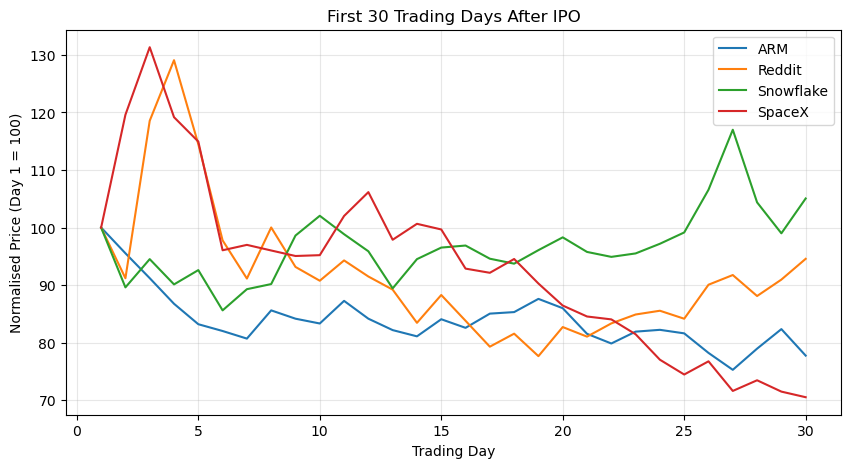

In [63]:

import matplotlib.pyplot as plt
import pandas as pd

# Combine IPO closing prices
ipo_prices = pd.DataFrame({
    "ARM": arm_30["Close"].iloc[:, 0].to_numpy(),
    "Reddit": reddit_30["Close"].iloc[:, 0].to_numpy(),
    "Snowflake": snow_30["Close"].iloc[:, 0].to_numpy(),
    "SpaceX": spacex_30["Close"].iloc[:, 0].to_numpy()
})

# Set every IPO's first closing price to 100
normalized_prices = ipo_prices.div(ipo_prices.iloc[0]) * 100

# Trading day numbers
normalized_prices.index = range(1, len(normalized_prices) + 1)

# Plot price paths
normalized_prices.plot(figsize=(10, 5))

plt.title("First 30 Trading Days After IPO")
plt.xlabel("Trading Day")
plt.ylabel("Normalised Price (Day 1 = 100)")
plt.grid(True, alpha=0.3)
plt.show()



### IPO Price Movement Analysis

The four IPOs followed different price patterns over 30 trading days.
SpaceX and ARM declined significantly, while Snowflake gained value.
Reddit experienced sharp early price movements before declining.

This shows that IPO performance is uncertain, motivating us to
use Monte Carlo simulation to examine possible future outcomes.



### Step 3: Understanding Daily Return Distribution

We know the average returns and volatility of the four IPOs, but we
don't know how often they experienced small or large price changes.

We will plot the daily returns to see how frequently gains and
losses occurred, including extreme movements.

**Why?** This helps us choose how to generate realistic price
movements in our Monte Carlo simulation and understand the risks
of buying after an IPO.


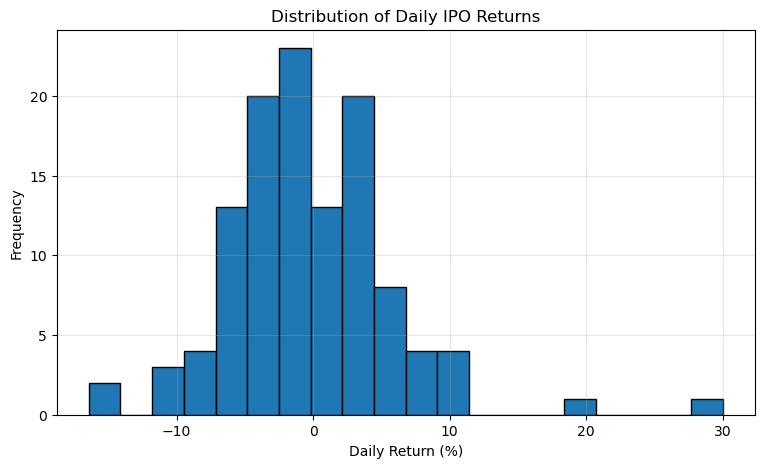

In [68]:

# Combine daily returns from all four IPOs
all_returns = pd.concat([
    arm_returns_clean.iloc[:, 0],
    reddit_returns.iloc[:, 0],
    snow_returns.iloc[:, 0],
    spacex_returns.iloc[:, 0]
], ignore_index=True)

# Plot the distribution
plt.figure(figsize=(9, 5))

plt.hist(all_returns * 100, bins=20, edgecolor="black")

plt.title("Distribution of Daily IPO Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)

plt.show()



### Interpretation of Daily Return Distribution

Most IPO daily returns were close to zero, but some days showed
large gains and losses.

This matters for Monte Carlo because we want our simulations to
include both normal price movements and extreme market changes,
rather than underestimating risk.



### Step 4: Monte Carlo Simulation (Historical Bootstrapping)

We randomly select historical daily returns from the four IPOs to
generate 10,000 possible price paths over 30 trading days.

**Why?** To understand possible profits, losses and risks, including
extreme price movements, before comparing different buying strategies.

**Note:** These are simulated outcomes, not future price predictions.


Simulation shape: (10000, 31)


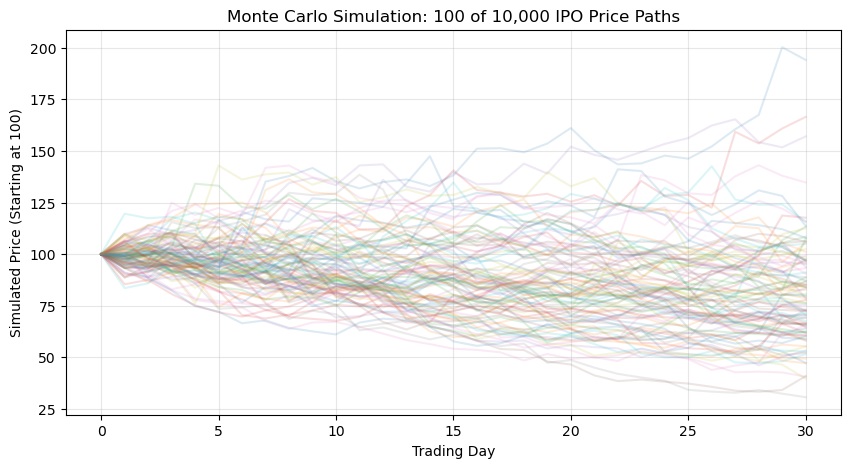

In [71]:

import numpy as np
import matplotlib.pyplot as plt

# Make results reproducible
np.random.seed(42)

# Simulation settings
n_simulations = 10000
n_days = 30
initial_price = 100

# Randomly sample historical IPO returns
simulated_returns = np.random.choice(
    all_returns.dropna().to_numpy(),
    size=(n_simulations, n_days),
    replace=True
)

# Convert returns into simulated prices
simulated_prices = initial_price * np.cumprod(
    np.column_stack([
        np.ones(n_simulations),
        1 + simulated_returns
    ]),
    axis=1
)

print("Simulation shape:", simulated_prices.shape)

# Plot the first 100 simulated paths
plt.figure(figsize=(10, 5))

for i in range(100):
    plt.plot(simulated_prices[i], alpha=0.15)

plt.title("Monte Carlo Simulation: 100 of 10,000 IPO Price Paths")
plt.xlabel("Trading Day")
plt.ylabel("Simulated Price (Starting at 100)")
plt.grid(True, alpha=0.3)
plt.show()



### Step 5: Analysing Monte Carlo Results

We generated 10,000 possible IPO price paths. Now we want to
understand how profitable or risky these outcomes are.

We calculate:
- **Average return:** How much we gain or lose on average.
- **Probability of loss:** How often we lose money.
- **Worst 5% of outcomes:** How much we could lose in bad scenarios.

**Why?** To understand the potential rewards and risks of investing
in an IPO before comparing different buying strategies.

**Note:** These results depend on our simulation assumptions.


In [76]:

# Get the final price from all 10,000 simulations
final_prices = simulated_prices[:, -1]

# Calculate returns from starting price of 100
final_returns = (final_prices / initial_price) - 1

# Calculate performance metrics
average_return = np.mean(final_returns) * 100
probability_loss = np.mean(final_returns < 0) * 100
worst_5_percent = np.percentile(final_returns, 5) * 100

# Display results in a DataFrame
mc_results = pd.DataFrame({
    "Metric": [
        "Average simulated return",
        "Probability of loss",
        "5th percentile return"
    ],
    "Result (%)": [
        average_return,
        probability_loss,
        worst_5_percent
    ]
})

mc_results["Result (%)"] = mc_results["Result (%)"].round(2)

display(mc_results)


,Metric,Result (%)
0,Average simulated return,-10.03
1,Probability of loss,69.64
2,5th percentile return,-48.99



### Monte Carlo Results Interpretation

Our 10,000 simulations showed an average loss of 10.03% over
30 trading days, with 69.64% of scenarios ending in a loss.

In the worst 5% of scenarios, losses were approximately 49% or more.

**Conclusion:** The simulated IPO investment showed significant
downside risk, but we still need to test whether waiting before
buying improves the results.



### Step 6: Comparing IPO Entry Strategies

We will compare three strategies:
- Strategy A: Buy on Day 1
- Strategy B: Buy on Day 3
- Strategy C: Buy on Day 5

All strategies will sell on Day 30.

**Why?** To see whether waiting before buying reduces the
risk of losses or improves returns.

**Note:** Our initial simulation mixes historical daily returns
randomly, so it cannot yet capture the special risks of an
IPO's first few days.


In [82]:

# Compare different IPO entry strategies
results = []

for entry_day in [0, 3, 5]:

    # Buy at simulated price on entry day
    buy_price = simulated_prices[:, entry_day]

    # Sell at the end of Day 30
    sell_price = simulated_prices[:, 30]

    # Calculate return for each simulation
    returns = (sell_price / buy_price) - 1

    results.append({
        "Entry day": entry_day,
        "Average return (%)": np.mean(returns) * 100,
        "Probability of loss (%)": np.mean(returns < 0) * 100,
        "5th percentile return (%)": np.percentile(returns, 5) * 100
    })

strategy_results = pd.DataFrame(results)

display(strategy_results.round(2))


,Entry day,Average return (%),Probability of loss (%),5th percentile return (%)
0,0,-10.03,69.64,-48.99
1,3,-9.07,68.87,-47.23
2,5,-8.40,68.26,-45.43



### Interpretation: Comparing Entry Strategies

Buying on Day 5 produced the smallest average simulated loss
(-8.40%) and lowest probability of loss (68.26%).

However, this does not prove that waiting five days is better,
because waiting also reduces the number of days invested.

**Research gap:** We need to account for how IPO returns and
volatility change during the first few trading days before
deciding which entry strategy is best.
